#### ***Persisitence In LangGraph***
- ***The mechanism that saves and resumes an AI agent's state across multiple turns.***

In [1]:
import warnings
warnings.filterwarnings("ignore")

from langgraph.graph import START,END,StateGraph
from typing import TypedDict
from langchain_groq import ChatGroq
from langgraph.checkpoint.memory import InMemorySaver

from dotenv import load_dotenv
load_dotenv()

True

In [2]:
llm = ChatGroq(
    model="openai/gpt-oss-120b",
    temperature=0
)

In [3]:
# Define State 
class JokeState(TypedDict):
    topic:str
    joke:str 
    explaination:str

# Node_1: Genrate Joke 
def generate_joke(state:JokeState):
    prompt = f'generate a joke on the topic {state["topic"]}'
    response = llm.invoke(prompt).content

    return {'joke': response}

# Node_2: Generate Explaination
def generate_explaination(state:JokeState):
    prompt = f'write an explaination for the joke - {state["joke"]}'
    response = llm.invoke(prompt).content

    return {'explaination': response}

In [4]:
# Build Graph 
graph = StateGraph(JokeState)

graph.add_node('generate_joke',generate_joke)
graph.add_node('generate_explaination',generate_explaination)

graph.add_edge(START,'generate_joke')
graph.add_edge('generate_joke','generate_explaination')
graph.add_edge('generate_explaination',END)

checkpointer = InMemorySaver()

workflow = graph.compile(checkpointer=checkpointer)

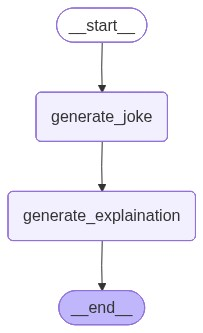

In [5]:
# Visualize Our Workflow
from IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())

In [6]:
config1 = {"configurable": {"thread_id": "1"}}
workflow.invoke({'topic':'Football'}, config=config1)

{'topic': 'Football',
 'joke': 'Why did the football team go to the bank?\n\nBecause they wanted to get their **quarter‑back**!',
 'explaination': '**Why did the football team go to the bank?  \nBecause they wanted to get their “quarter‑back!”**\n\n### The wordplay\n\n1. **Quarterback (football)**  \n   - In American football, the *quarterback* is the player who lines up behind the center and usually leads the offense, calling plays and throwing the ball.  \n   - The term is a single word that describes a specific position on the field.\n\n2. **Quarter + back (banking)**  \n   - A *quarter* is a 25‑cent coin in U.S. currency.  \n   - To *back* something can mean to support it, to give it a “backing,” or, in a more literal sense, to *put* something behind you (e.g., “back a horse” in betting).  \n   - In a bank, you go to *get* or *deposit* money—coins, bills, etc. So a person might go to the bank to obtain a quarter.\n\n3. **The pun**  \n   - The joke pretends that the football team is

In [7]:
workflow.get_state(config1)

StateSnapshot(values={'topic': 'Football', 'joke': 'Why did the football team go to the bank?\n\nBecause they wanted to get their **quarter‑back**!', 'explaination': '**Why did the football team go to the bank?  \nBecause they wanted to get their “quarter‑back!”**\n\n### The wordplay\n\n1. **Quarterback (football)**  \n   - In American football, the *quarterback* is the player who lines up behind the center and usually leads the offense, calling plays and throwing the ball.  \n   - The term is a single word that describes a specific position on the field.\n\n2. **Quarter + back (banking)**  \n   - A *quarter* is a 25‑cent coin in U.S. currency.  \n   - To *back* something can mean to support it, to give it a “backing,” or, in a more literal sense, to *put* something behind you (e.g., “back a horse” in betting).  \n   - In a bank, you go to *get* or *deposit* money—coins, bills, etc. So a person might go to the bank to obtain a quarter.\n\n3. **The pun**  \n   - The joke pretends that t

In [8]:
list(workflow.get_state_history(config1))

[StateSnapshot(values={'topic': 'Football', 'joke': 'Why did the football team go to the bank?\n\nBecause they wanted to get their **quarter‑back**!', 'explaination': '**Why did the football team go to the bank?  \nBecause they wanted to get their “quarter‑back!”**\n\n### The wordplay\n\n1. **Quarterback (football)**  \n   - In American football, the *quarterback* is the player who lines up behind the center and usually leads the offense, calling plays and throwing the ball.  \n   - The term is a single word that describes a specific position on the field.\n\n2. **Quarter + back (banking)**  \n   - A *quarter* is a 25‑cent coin in U.S. currency.  \n   - To *back* something can mean to support it, to give it a “backing,” or, in a more literal sense, to *put* something behind you (e.g., “back a horse” in betting).  \n   - In a bank, you go to *get* or *deposit* money—coins, bills, etc. So a person might go to the bank to obtain a quarter.\n\n3. **The pun**  \n   - The joke pretends that 

In [9]:
config2 = {"configurable": {"thread_id": "2"}}
workflow.invoke({'topic':'Cricket'}, config=config2)

{'topic': 'Cricket',
 'joke': 'Why did the cricket team bring a ladder to the match?\n\nBecause they heard the scores were *going through the roof* and wanted to make sure they could *catch* the high‑flying runs! 🏏😄',
 'explaination': '**Explanation of the joke**\n\n> **Why did the cricket team bring a ladder to the match?**  \n> **Because they heard the scores were *going through the roof* and wanted to make sure they could *catch* the high‑flying runs!** 🏏😄  \n\n---\n\n### 1. The phrase “going through the roof”\n\n- **Literal meaning:** If something “goes through the roof,” it actually breaks through the ceiling of a building.  \n- **Figurative (idiomatic) meaning:** In everyday English, “the scores are going through the roof” is a colorful way of saying that the scores are *rising very quickly* or *becoming extremely high*.\n\nSo the joke starts by playing on that idiom: the team *hears* that the scores are “going through the roof,” which makes them think they need a way to reach th

In [10]:
workflow.get_state(config2)

StateSnapshot(values={'topic': 'Cricket', 'joke': 'Why did the cricket team bring a ladder to the match?\n\nBecause they heard the scores were *going through the roof* and wanted to make sure they could *catch* the high‑flying runs! 🏏😄', 'explaination': '**Explanation of the joke**\n\n> **Why did the cricket team bring a ladder to the match?**  \n> **Because they heard the scores were *going through the roof* and wanted to make sure they could *catch* the high‑flying runs!** 🏏😄  \n\n---\n\n### 1. The phrase “going through the roof”\n\n- **Literal meaning:** If something “goes through the roof,” it actually breaks through the ceiling of a building.  \n- **Figurative (idiomatic) meaning:** In everyday English, “the scores are going through the roof” is a colorful way of saying that the scores are *rising very quickly* or *becoming extremely high*.\n\nSo the joke starts by playing on that idiom: the team *hears* that the scores are “going through the roof,” which makes them think they nee

- ***Time Travel***
   - ***The ability to "rewind" an agent's state history to an older checkpoint, edit a past instruction, and fork a brand-new conversation branch.***

In [11]:
workflow.get_state({"configurable": {"thread_id": "2", "checkpoint_id": "1f175feb-1ca4-683b-8001-c9b7dce49260"}})

StateSnapshot(values={}, next=(), config={'configurable': {'thread_id': '2', 'checkpoint_id': '1f175feb-1ca4-683b-8001-c9b7dce49260'}}, metadata=None, created_at=None, parent_config=None, tasks=())

In [12]:
list(workflow.get_state_history(config2))

[StateSnapshot(values={'topic': 'Cricket', 'joke': 'Why did the cricket team bring a ladder to the match?\n\nBecause they heard the scores were *going through the roof* and wanted to make sure they could *catch* the high‑flying runs! 🏏😄', 'explaination': '**Explanation of the joke**\n\n> **Why did the cricket team bring a ladder to the match?**  \n> **Because they heard the scores were *going through the roof* and wanted to make sure they could *catch* the high‑flying runs!** 🏏😄  \n\n---\n\n### 1. The phrase “going through the roof”\n\n- **Literal meaning:** If something “goes through the roof,” it actually breaks through the ceiling of a building.  \n- **Figurative (idiomatic) meaning:** In everyday English, “the scores are going through the roof” is a colorful way of saying that the scores are *rising very quickly* or *becoming extremely high*.\n\nSo the joke starts by playing on that idiom: the team *hears* that the scores are “going through the roof,” which makes them think they ne

- ***Updating State***

In [13]:
workflow.update_state({"configurable": {"thread_id": "2", "checkpoint_id": "1f175feb-1ca4-683b-8001-c9b7dce49260", "checkpoint_ns": ""}}, {'topic':'Tenis'})

{'configurable': {'thread_id': '2',
  'checkpoint_ns': '',
  'checkpoint_id': '1f176007-470f-6af6-8000-bd76566c4790'}}

In [14]:
list(workflow.get_state_history(config2))

[StateSnapshot(values={'topic': 'Tenis'}, next=('generate_joke',), config={'configurable': {'thread_id': '2', 'checkpoint_ns': '', 'checkpoint_id': '1f176007-470f-6af6-8000-bd76566c4790'}}, metadata={'thread_id': '2', 'checkpoint_id': '1f175feb-1ca4-683b-8001-c9b7dce49260', 'checkpoint_ns': '', 'source': 'update', 'step': 0, 'writes': {'__start__': {'topic': 'Tenis'}}, 'parents': {}}, created_at='2026-07-02T10:26:15.083493+00:00', parent_config={'configurable': {'thread_id': '2', 'checkpoint_ns': '', 'checkpoint_id': '1f175feb-1ca4-683b-8001-c9b7dce49260'}}, tasks=(PregelTask(id='843d8e54-c920-6580-4910-79a1deca1227', name='generate_joke', path=('__pregel_pull', 'generate_joke'), error=None, interrupts=(), state=None, result=None),)),
 StateSnapshot(values={'topic': 'Cricket', 'joke': 'Why did the cricket team bring a ladder to the match?\n\nBecause they heard the scores were *going through the roof* and wanted to make sure they could *catch* the high‑flying runs! 🏏😄', 'explaination': 

- ***Fault Tolerance***
   - ***The system's ability to recover gracefully when an external API, database, or LLM call crashes mid-run.***

In [15]:
from langgraph.graph import StateGraph,START,END 
from langgraph.checkpoint.memory import InMemorySaver
from typing  import TypedDict
import time 

# Define State 
class CrashState(TypedDict):
    input:str
    step1:str
    step2:str

In [16]:
# Define steps
def step_1(state: CrashState) -> CrashState:
    print("✅ Step 1 executed")
    return {"step1": "done", "input": state["input"]}

def step_2(state: CrashState) -> CrashState:
    print("⏳ Step 2 hanging... now manually interrupt from the notebook toolbar (STOP button)")
    time.sleep(30)  # Simulate long-running hang
    return {"step2": "done"}

def step_3(state: CrashState) -> CrashState:
    print("✅ Step 3 executed")
    return {"done": True}

In [17]:
# Build Graph 
builder = StateGraph(CrashState)
builder.add_node("step_1", step_1)
builder.add_node("step_2", step_2)
builder.add_node("step_3", step_3)

builder.set_entry_point("step_1")
builder.add_edge("step_1", "step_2")
builder.add_edge("step_2", "step_3")
builder.add_edge("step_3", END)

checkpointer = InMemorySaver()
graph = builder.compile(checkpointer=checkpointer)

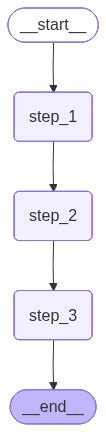

In [18]:
# Visualize Our Graph 
from IPython.display import  Image 
Image(graph.get_graph().draw_mermaid_png())

In [21]:
try:
    print("▶️ Running graph: Please manually interrupt during Step 2...")
    graph.invoke({"input": "start"}, config={"configurable": {"thread_id": 'thread-1'}})
except KeyboardInterrupt:
    print("❌ Kernel manually interrupted (crash simulated).")

▶️ Running graph: Please manually interrupt during Step 2...
✅ Step 1 executed
⏳ Step 2 hanging... now manually interrupt from the notebook toolbar (STOP button)
✅ Step 3 executed


InvalidUpdateError: Expected node step_3 to update at least one of ['input', 'step1', 'step2'], got {'done': True}

In [ ]:
print("\n🔁 Re-running the graph to demonstrate fault tolerance...")
final_state = graph.invoke(None, config={"configurable": {"thread_id": 'thread-1'}})
print("\n✅ Final State:", final_state)


🔁 Re-running the graph to demonstrate fault tolerance...


EmptyInputError: Received no input for __start__

In [22]:
list(graph.get_state_history({"configurable": {"thread_id": 'thread-1'}}))

[StateSnapshot(values={'input': 'start', 'step1': 'done', 'step2': 'done'}, next=('step_3',), config={'configurable': {'thread_id': 'thread-1', 'checkpoint_ns': '', 'checkpoint_id': '1f176009-3847-6700-8002-020da3b69b63'}}, metadata={'source': 'loop', 'writes': {'step_2': {'step2': 'done'}}, 'thread_id': 'thread-1', 'step': 2, 'parents': {}}, created_at='2026-07-02T10:27:07.220556+00:00', parent_config={'configurable': {'thread_id': 'thread-1', 'checkpoint_ns': '', 'checkpoint_id': '1f176008-1a1f-6bd5-8001-1789c11bb3b1'}}, tasks=(PregelTask(id='9e3df661-d0d4-17dd-fcc4-f66ec58f9af6', name='step_3', path=('__pregel_pull', 'step_3'), error='InvalidUpdateError("Expected node step_3 to update at least one of [\'input\', \'step1\', \'step2\'], got {\'done\': True}")', interrupts=(), state=None, result=None),)),
 StateSnapshot(values={'input': 'start', 'step1': 'done'}, next=('step_2',), config={'configurable': {'thread_id': 'thread-1', 'checkpoint_ns': '', 'checkpoint_id': '1f176008-1a1f-6bd